# EDA

## 1. Load and sanity checks

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from concurrent.futures import ThreadPoolExecutor
import torch
import timm
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components

SEED = 21

DATA_DIR = '/kaggle/input/competitions/cats-and-dogs'

train = pd.read_csv(f'{DATA_DIR}/train.csv')
test = pd.read_csv(f'{DATA_DIR}/test.csv')
train['path'] = DATA_DIR + '/train/' + train.image_id + '.jpg'
test['path'] = DATA_DIR + '/test/' + test.image_id + '.jpg'

print('train:', len(train), '| test:', len(test))
print('missing values in train:', int(train.isna().sum().sum()))
print('duplicated ids:', int(train.image_id.duplicated().sum()), int(test.image_id.duplicated().sum()))
print('all image files exist:', all(os.path.exists(p) for p in train.path) and all(os.path.exists(p) for p in test.path))

train: 12260 | test: 18673
missing values in train: 0
duplicated ids: 0 0
all image files exist: True


### Unique labels

In [2]:
label_cols = [c for c in train.columns if c not in ('image_id', 'path')]
pet_cols = [c for c in label_cols if c not in ('Cat', 'Dog')]

print('label columns:', label_cols)

label columns: ['Cat', 'Dog', 'Moris', 'Motya', 'Biatrix']


## 2. Image statistics

In [3]:
def scan(path):
    im = Image.open(path)
    w, h, mode = im.size[0], im.size[1], im.mode
    im.draft('RGB', (128, 128))
    small = im.convert('RGB').resize((32, 32))
    rgb = np.asarray(small, dtype=np.float32).mean((0, 1)) / 255
    hsv = np.asarray(small.convert('HSV'), dtype=np.float32).mean((0, 1)) / 255
    return dict(w=w, h=h, mode=mode, r=rgb[0], g=rgb[1], b=rgb[2], sat=hsv[1], val=hsv[2])

df = pd.concat([train.assign(split='train'), test.assign(split='test')], ignore_index=True)
with ThreadPoolExecutor(os.cpu_count()) as ex:
    stats = pd.DataFrame(list(ex.map(scan, df.path)))
df = pd.concat([df, stats], axis=1)
tr = df[df.split == 'train'].reset_index(drop=True)
te = df[df.split == 'test'].reset_index(drop=True)

print('colour modes:', df.groupby('split')['mode'].value_counts().to_dict())
print('image sizes (w, h):', df[['split', 'w', 'h']].drop_duplicates().values.tolist())

colour modes: {('test', 'RGB'): 18673, ('train', 'RGB'): 12260}
image sizes (w, h): [['train', 450, 375], ['test', 450, 375]]


## 3. Class distribution

,positives,share_%
Cat,5077,41.41
Dog,5025,40.99
Moris,56,0.46
Motya,42,0.34
Biatrix,41,0.33


images with no label: 2162 (17.6%)
images with 2+ labels: 125


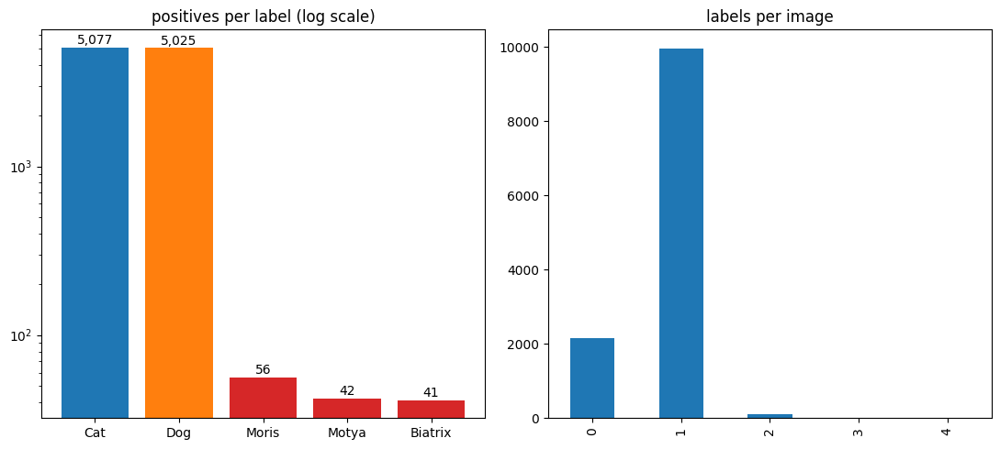

,Cat,Dog,Moris,Motya,Biatrix,images
0,1,0,0,0,0,4989
1,0,1,0,0,0,4984
2,0,0,0,0,0,2162
3,1,0,1,0,0,42
4,0,1,0,0,1,37
5,1,0,0,1,0,32
6,1,0,1,1,0,10
7,1,1,1,0,1,4


In [4]:
Y = train[label_cols].astype(int)
n_pos = Y.sum()
n_lab = Y.sum(axis=1)

summary = pd.DataFrame({'positives': n_pos, 'share_%': (n_pos / len(Y) * 100).round(2)})
display(summary)
print('images with no label:', int((n_lab == 0).sum()), f'({(n_lab == 0).mean():.1%})')
print('images with 2+ labels:', int((n_lab >= 2).sum()))

fig, ax = plt.subplots(1, 2, figsize=(11, 5))
ax[0].bar(label_cols, n_pos, color=[{'Cat': 'C0', 'Dog': 'C1'}.get(c, 'C3') for c in label_cols])
ax[0].set_yscale('log')
for i, v in enumerate(n_pos):
    ax[0].text(i, v * 1.05, f'{v:,}', ha='center')
ax[0].set_title('positives per label (log scale)')
n_lab.value_counts().sort_index().plot.bar(ax=ax[1], color='C0')
ax[1].set_title('labels per image')
plt.tight_layout()
plt.show()

Y.value_counts().rename('images').reset_index()

## 4. Label structure

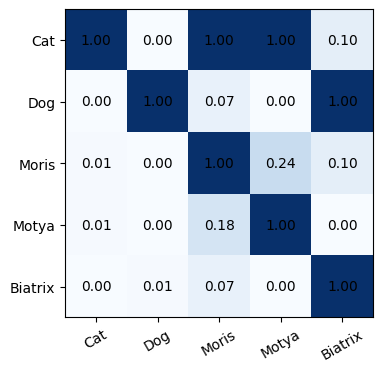

In [5]:
co = Y.T.values @ Y.values
cond = pd.DataFrame(co / np.diag(co)[None, :], index=label_cols, columns=label_cols)

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(cond.values, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(label_cols)), label_cols, rotation=30)
ax.set_yticks(range(len(label_cols)), label_cols)
for i in range(len(label_cols)):
    for j in range(len(label_cols)):
        ax.text(j, i, f'{cond.values[i, j]:.2f}', ha='center', va='center')
ax.grid(False)
plt.show()

## 5. Rare classes — samples

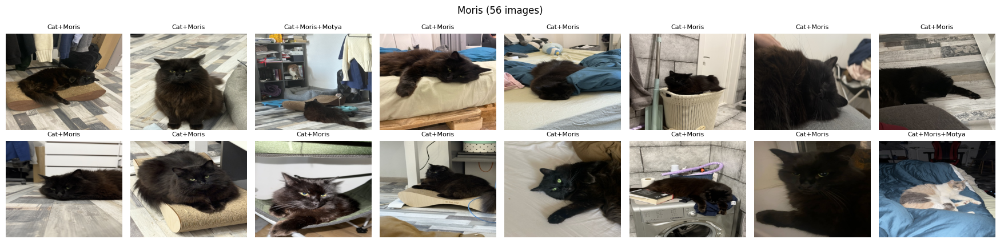

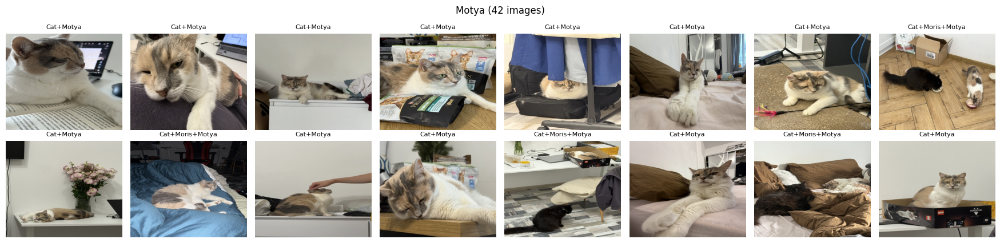

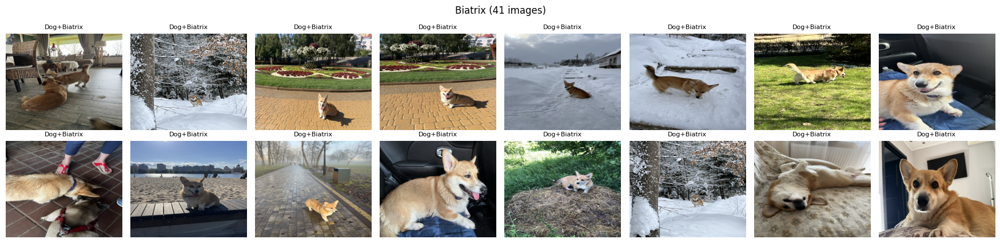

In [6]:
def title(row):
    return '+'.join(l for l in label_cols if row[l] == 1) or 'none'

def show(d, name, ncols=8, n=16):
    d = d.sample(min(n, len(d)), random_state=SEED)
    nrows = int(np.ceil(len(d) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(2.2 * ncols, 2.2 * nrows), squeeze=False)
    for a in axes.ravel():
        a.axis('off')
    for a, (_, row) in zip(axes.ravel(), d.iterrows()):
        a.imshow(Image.open(row.path))
        a.set_title(title(row), fontsize=8)
    fig.suptitle(name)
    plt.tight_layout()
    plt.show()

for p in pet_cols:
    show(tr[tr[p] == 1], f'{p} ({int(tr[p].sum())} images)')

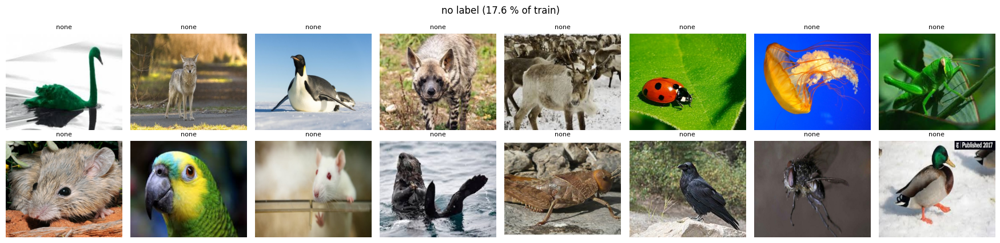

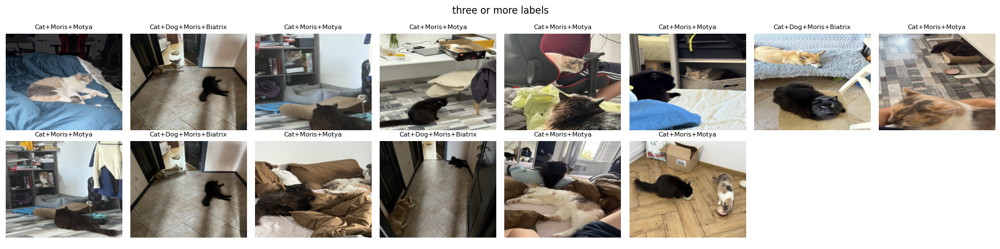

In [7]:
show(tr[tr[label_cols].sum(axis=1) == 0], 'no label (17.6 % of train)')
show(tr[tr[label_cols].sum(axis=1) >= 3], 'three or more labels')

## 6. Duplicates and train/test overlap

In [8]:
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

model = timm.create_model("resnet18.a1_in1k", pretrained=True, num_classes=0).eval().to(DEVICE)
tfm = timm.data.create_transform(**timm.data.resolve_data_config({}, model=model))

def load(path):
    im = Image.open(path)
    im.draft('RGB', (320, 320))
    return tfm(im.convert('RGB'))

feats = []
with ThreadPoolExecutor(os.cpu_count()) as ex, torch.no_grad():
    for s in range(0, len(df), 128):
        x = torch.stack(list(ex.map(load, df.path[s:s + 128])))
        feats.append(model(x.to(DEVICE)).cpu())
feats = torch.cat(feats).numpy()

THRESHOLD = 0.95
knn = NearestNeighbors(radius=1 - THRESHOLD, metric="cosine", algorithm="brute").fit(feats)
df["cluster"] = connected_components(knn.radius_neighbors_graph(feats), directed=False)[1]


tr = df[df.split == 'train'].reset_index(drop=True)
te = df[df.split == 'test'].reset_index(drop=True)

counts = df.groupby('cluster').split.value_counts().unstack(fill_value=0)
counts['n'] = counts.sum(axis=1)
copies = counts[counts.n > 1]
print(f'images that have a copy: {int(copies.n.sum())} ({copies.n.sum() / len(df):.1%}) | groups of copies: {len(copies)} | largest: {counts.n.max()}')
print('test images with a copy in train:', int(te.cluster.isin(tr.cluster).sum()), f'({te.cluster.isin(tr.cluster).mean():.1%})')

model.safetensors: reconstructing file:   0%|          |  0.00B / 46.8MB            

model.safetensors: downloading bytes:           |  0.00B            

images that have a copy: 849 (2.7%) | groups of copies: 420 | largest: 5
test images with a copy in train: 214 (1.1%)


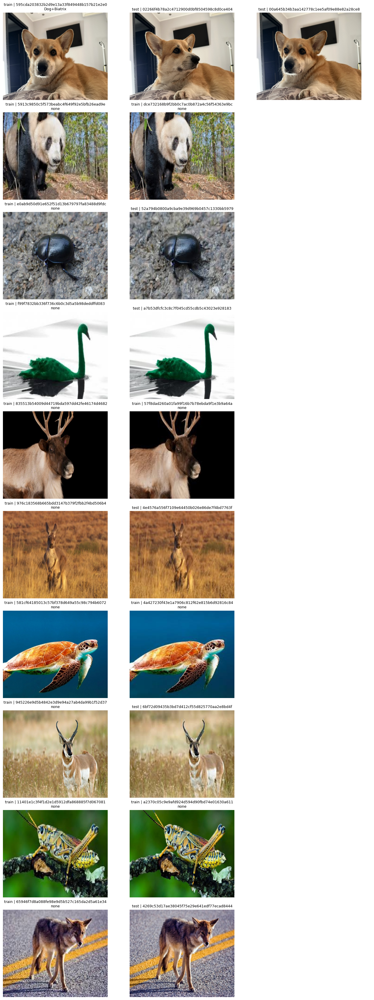

In [11]:
rng = np.random.RandomState(SEED)
triple = copies.index[copies.n == 3][:1].tolist()
pairs = copies.index[copies.n == 2]
groups = triple + rng.choice(pairs, 10 - len(triple), replace=False).tolist()

fig, axes = plt.subplots(len(groups), 3, figsize=(13, 3.4 * len(groups)), squeeze=False, layout='constrained')
for ax_row, c in zip(axes, groups):
    for a in ax_row:
        a.axis('off')
    for a, (_, row) in zip(ax_row, df[df.cluster == c].iterrows()):
        a.imshow(Image.open(row.path))
        a.set_title(f'{row.split} | {row.image_id}' + (f'\n{title(row)}' if row.split == 'train' else ''), fontsize=9, pad=6)
plt.show()